In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as  mdates
import numpy as np

In [3]:
df = pd.read_csv('data/euriborkorot.csv', parse_dates=True)
df.columns = ['maturity', 'month', 'datetime', 'euribor']
df['datetime'] = pd.to_datetime(df['datetime'], format='%m/%d/%Y %H:%M:%S', errors='coerce')
df.head()
df.dtypes

maturity               str
month                  str
datetime    datetime64[us]
euribor                str
dtype: object

In [4]:
# Set datetime to index, filter out maturities other than 12 months leave out month column.
df.set_index('datetime', inplace=True)
df = df[df['maturity'] == '12 kk']
df = df[['maturity', 'euribor']]
df.head()

,maturity,euribor
datetime,,
2026-05-04,12 kk,2.883
2026-05-05,12 kk,2.837
2026-05-06,12 kk,2.867
2026-05-07,12 kk,2.795
2026-05-08,12 kk,2.708


In [5]:
df['euribor'] = df['euribor'].astype('float32')
df.dtypes

maturity        str
euribor     float32
dtype: object

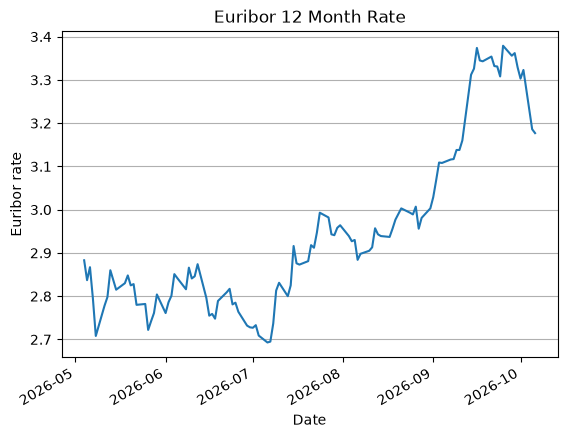

In [15]:
title = 'Euribor 12 Month Rate'
x_label = 'Date'
y_label = 'Euribor rate'
ax = df['euribor'].plot(title=title)
ax.set(xlabel=x_label, ylabel=y_label)
ax.yaxis.grid(True)


Augmented Dickey-Fuller Test: 9.417065471120215e-08


C:\Users\Miro\AppData\Local\Temp\ipykernel_12920\2109275284.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adfuller_result = adfuller(df['euribor_diff'].diff().dropna())


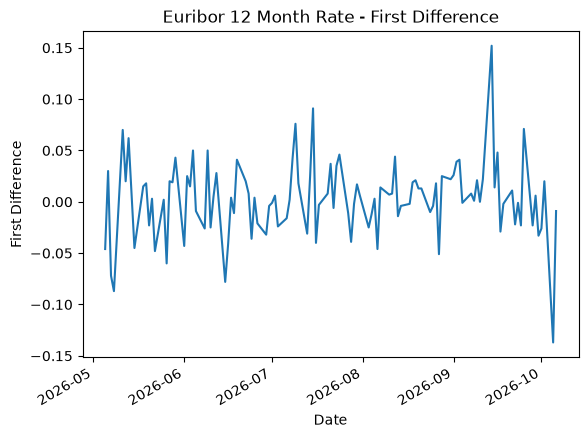

In [ ]:
# Euribor not stationary, take first difference to make it stationary.
from statsmodels.tsa.statespace.tools import diff
df['euribor_diff'] = diff(df['euribor'], k_diff=1)
df['euribor_diff'].plot(title='Euribor 12 Month Rate - First Difference', ylabel='First Difference', xlabel='Date')

Augmented Dickey-Fuller Test: 9.417065471120215e-08


C:\Users\Miro\AppData\Local\Temp\ipykernel_12920\379948941.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adfuller_result = adfuller(df['euribor_diff'].diff().dropna())


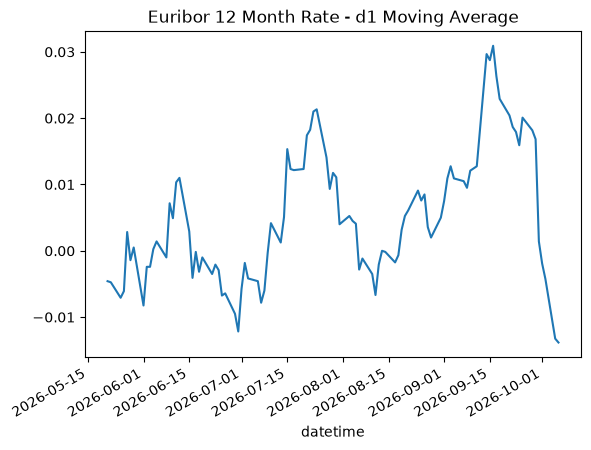

In [24]:
df['euribor_diff_ma'] = df['euribor_diff'].rolling(12).mean()
df['euribor_diff_ma'].plot(title='Euribor 12 Month Rate - d1 Moving Average')

from statsmodels.tsa.stattools import adfuller
adfuller_result = adfuller(df['euribor_diff'].diff().dropna())
print(f"Augmented Dickey-Fuller Test: {adfuller_result[1]}")

In [ ]:
# Augmented Dickey-Fuller Test: <0.05, data is stationary and we can proceed to fit an ARIMA model.
# 12-Month Euribor Rate seems to exhibit volatility clustering

In [ ]:
#Fit ARIMA model